# LangGraph agent for vehicle safety intelligence: analysis

A vehicle-safety analyst asks questions such as *"How many complaints about the brakes of the 2024 Toyota Tacoma has
NHTSA received, and is there a recall that covers this problem?"*. This notebook evaluates a LangGraph agent that
answers them from NHTSA's public complaint and recall files with a small local LLM (`qwen3:4b` through Ollama):

`classify` (route: sql / semantic / both) -> `plan` (Pydantic-validated tool calls, retried with the validator's
messages) -> `execute` (parameterised DuckDB SQL, FAISS recall search) -> `answer` (cited) -> `check_grounding`
(citations and numbers, retried) -> answer, or `decline` when no valid tool call can be formed.

Every number below is read from `reports/results/`, written by `scripts/run_pipeline.py`. The 50 test questions were
run once, after prompts and validation rules had been developed on a separate set of development questions (other
vehicles, other random seed).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 180)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['data', 'eval', 'agent', 'llm_usage', 'timings_s']}

{'data': {'files': {'FLAT_RCL_POST_2010.zip': {'url': 'https://static.nhtsa.gov/odi/ffdd/rcl/FLAT_RCL_POST_2010.zip',
    'bytes': 15006062,
    'sha256': '0b66a333adf5b7d2b69c6b5c71e1807d8b9143a04b6673e42d3241e436a2f55c',
    'inner_timestamp': '2026-10-10 07:02'},
   'COMPLAINTS_RECEIVED_2025-2026.zip': {'url': 'https://static.nhtsa.gov/odi/ffdd/cmpl/COMPLAINTS_RECEIVED_2025-2026.zip',
    'bytes': 41351222,
    'sha256': 'cb6215233506a11c0409defd5df33990e3b27ddc3ee4f3b52a8b65ad1f572ee1',
    'inner_timestamp': '2026-10-09 09:35'}},
  'coverage': {'complaints_from': '2025-01-01',
   'complaints_to': '2026-10-07',
   'complaints': 135048,
   'recalls_from': '2010-01-01',
   'recalls_to': '2026-10-06',
   'recall_campaigns': 13673,
   'makes': 1033},
  'tables': {'recalls': 13673,
   'recall_vehicles': 93365,
   'recall_components': 16049,
   'complaints': 135048,
   'complaint_components': 199480}},
 'eval': {'n_questions': 50,
  'by_route': {'sql': 24, 'semantic': 14, 'both': 12},
  

## Data and a check against the live API

The database holds 13,673 vehicle recall campaigns reported since 2010 and 135,048 vehicle complaints received from
2025-01-01 to 2026-10-07 (NHTSA flat files). For the 20 vehicles that appear in the test questions, the recall
campaigns and the complaint counts were compared with `api.nhtsa.gov`:

- recall campaign sets are identical for all 19 vehicles the API answered (it returns HTTP 400 for the 2022 Ford
  F-150 Hybrid);
- complaint counts in the same date window agree for 17 of the 18 vehicles the API answered. For the 2017 Chevrolet
  Bolt EV the API returns only 6 of the 53 complaints in the flat file, all 6 of which are in the flat file; the gap
  is on the API side (it lists no Bolt EV complaints filed in 2024-2025).

In [2]:
cross = pd.read_csv(RES / 'api_crosscheck.csv')
cross[['make', 'model', 'model_year', 'api_status_recalls', 'recalls_db', 'recalls_api', 'recalls_both',
       'api_status_complaints', 'complaints_db', 'complaints_api_same_window']]

,make,model,model_year,api_status_recalls,recalls_db,recalls_api,recalls_both,api_status_complaints,complaints_db,complaints_api_same_window
0,POLESTAR,POLESTAR 2,2022,200,4,4.0,4.0,200,245,245.0
1,JEEP,CHEROKEE,2020,200,3,3.0,3.0,200,207,207.0
2,FORD,F-150,2024,200,11,11.0,11.0,400,175,NaN
3,CHEVROLET,SILVERADO 1500,2019,200,10,10.0,10.0,200,448,448.0
4,HONDA,CR-V,2017,200,7,7.0,7.0,200,241,241.0
5,JEEP,CHEROKEE,2015,200,11,11.0,11.0,200,105,105.0
6,KIA,EV6,2023,200,4,4.0,4.0,200,94,94.0
7,FORD,F-150 HYBRID,2022,400,0,NaN,NaN,400,58,NaN
8,CHEVROLET,BOLT EV,2017,200,4,4.0,4.0,200,53,6.0
9,CHRYSLER,PACIFICA,2017,200,11,11.0,11.0,200,269,269.0


## Evaluation set

50 questions from 9 templates, with gold answers computed by gold SQL written independently of the agent's
SQL compiler (`safetyagent/evalset.py`): 24 `sql` questions (counts, a top component, crash / fire counts, recall
counts, potentially affected units), 14 `semantic` questions (why was a vehicle recalled over a component, gold =
the matching campaign numbers) and 12 `both` questions (complaint count for a component and the recall that covers
it). Components are named in plain words ("rearview camera", "transmission") that the planner has to map to NHTSA
component families. Vehicles were sampled at random (seed 1) from vehicles with enough complaints or recalls and are
disjoint from the development questions (seed 0).

In [3]:
ev = pd.read_csv(RES / 'eval_set.csv')
display(ev.groupby(['route', 'template']).size().rename('questions').reset_index())
ev.groupby('template').first()[['question', 'gold_value', 'gold_campaigns']]

,route,template,questions
0,both,complaints_and_recall,12
1,semantic,recall_explain,14
2,sql,complaint_count,5
3,sql,component_complaints,4
4,sql,make_crash_count,2
5,sql,make_fire_count,2
6,sql,recall_count,4
7,sql,recall_units,3
8,sql,top_component,4


,question,gold_value,gold_campaigns
template,,,
complaint_count,How many complaints has NHTSA received about the 2022 Polestar Polestar 2?,245,None
complaints_and_recall,"How many complaints about the fuel system of the 2018 Alfa Romeo Giulia has NHTSA received, and is there a recall th...",6,25V586000
component_complaints,How many NHTSA complaints about the 2015 Jeep Cherokee involve its transmission?,60,None
make_crash_count,How many complaints received in 2025 about Toyota vehicles reported a crash?,230,None
make_fire_count,How many complaints received in 2025 about Tesla vehicles reported a fire?,20,None
recall_count,How many recall campaigns cover the 2021 GMC Sierra 1500?,7,None
recall_explain,"Why was the 2021 Cadillac Escalade recalled over its electrical system? Describe the defect, the risk and the remedy.",None,21V421000
recall_units,How many vehicles were potentially affected by Nissan recalls reported in 2025?,878920,None
top_component,Which component do owners of the 2017 Chrysler Pacifica complain about most often?,STEERING,None


## Headline: tools turn 0 of 50 into 43 of 50

The agent answers 43 of 50 questions correctly (0.86, 95% Wilson interval 0.74-0.93). The same model without tools
answers none (0 of 50; upper bound 0.07). Exact McNemar test on the 43 discordant questions: p < 1e-12.

Routing is perfect on these templated questions. Tool arguments are exactly right for 44 of 50 questions, the
evidence handed to the answer node contains the gold answer for exactly those 44, and the final answer is right for
43 of them.

In [4]:
summary = pd.read_csv(RES / 'summary_by_route.csv')
summary[['route', 'n', 'route_accuracy', 'plan_valid_first_try', 'plan_valid_after_retries', 'tool_args_exact',
         'evidence_contains_gold', 'answer_accuracy_first_draft', 'answer_accuracy', 'answer_ci_low', 'answer_ci_high',
         'closed_book_accuracy', 'latency_p50_s', 'latency_p95_s', 'llm_calls_mean']]

,route,n,route_accuracy,plan_valid_first_try,plan_valid_after_retries,tool_args_exact,evidence_contains_gold,answer_accuracy_first_draft,answer_accuracy,answer_ci_low,answer_ci_high,closed_book_accuracy,latency_p50_s,latency_p95_s,llm_calls_mean
0,sql,24,1.0,0.583,0.917,0.833,0.833,0.833,0.833,0.641,0.933,0.0,3.950,6.535,3.500
1,semantic,14,1.0,1.000,1.000,0.929,0.929,0.857,0.857,0.601,0.960,0.0,4.812,5.167,3.000
2,both,12,1.0,0.917,0.917,0.917,0.917,0.917,0.917,0.646,0.985,0.0,7.029,9.028,3.083
3,all,50,1.0,0.780,0.940,0.880,0.880,0.860,0.860,0.738,0.930,0.0,4.950,7.420,3.260


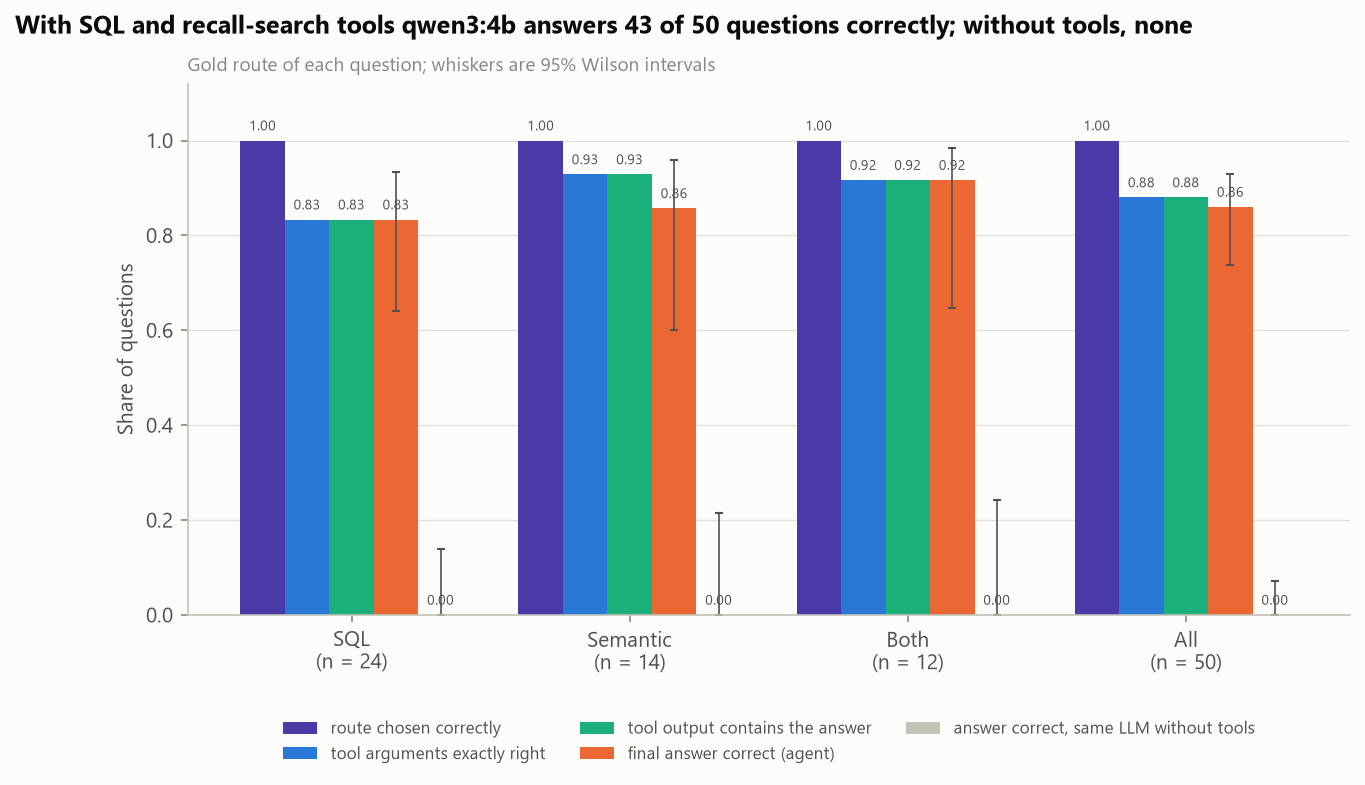

In [5]:
display(Image(FIG / '01_agent_scorecard.png'))

In [6]:
pd.read_csv(RES / 'comparisons.csv')

,comparison,n,accuracy_a,accuracy_b,only_a_correct,only_b_correct,p_value_exact_mcnemar
0,closed-book LLM (a) vs agent (b),50,0.00,0.86,0,43,0.0
1,agent first draft (a) vs after grounding retries (b),50,0.86,0.86,0,0,1.0


Without tools the model either says it has no access to the data or commits to something wrong: "0" or "1"
for counts, an invented recall number ("22001"), or a confident description of a recall for a different problem.

In [7]:
cb = pd.read_csv(RES / 'closed_book.csv').merge(ev[['qid', 'gold_value', 'gold_campaigns']], on='qid')
cb.groupby('template').first()[['answer', 'gold_value', 'gold_campaigns', 'correct']]

,answer,gold_value,gold_campaigns,correct
template,,,,
complaint_count,I don't have access to real-time or specific complaint data for the 2022 Polestar Polestar 2. NHTSA complaint data i...,245,None,False
complaints_and_recall,The NHTSA complaint data for the 2018 Alfa Romeo Giulia fuel system issue shows 12 complaints received from 2025-01-...,6,25V586000,False
component_complaints,I don't have access to real-time or specific NHTSA complaint data for the 2015 Jeep Cherokee transmission complaints...,60,None,False
make_crash_count,0,230,None,False
make_fire_count,0,20,None,False
recall_count,The specific number of recall campaigns for the 2021 GMC Sierra 1500 is not directly available in the provided knowl...,7,None,False
recall_explain,The 2021 Cadillac Escalade was recalled due to a potential electrical short circuit in the vehicle's electrical syst...,None,21V421000,False
recall_units,"The question asks for the number of vehicles potentially affected by Nissan recalls reported in 2025. However, based...",878920,None,False
top_component,The specific component that owners of the 2017 Chrysler Pacifica complain about most often based on NHTSA data is no...,STEERING,None,False


## Where the 7 misses come from

Six misses start in the tool call and one in answer synthesis:

- **Dropped model suffixes (3, all declined).** For "2019 Chevrolet Silverado 1500", "2021 GMC Sierra 1500" and
  "2020 Chevrolet Silverado 3500" the planner writes `SILVERADO` / `SIERRA`. The validator rejects the vehicle and
  lists the valid models for that year, including the right one, but the model repeats the same call three times and
  the agent declines. These are abstentions, not wrong numbers.
- **A valid but wrong vehicle (2).** "2022 Ford F-150 Hybrid" becomes `F-150` (which exists, so validation passes):
  110 complaints instead of 22. "2022 Genesis GV70" becomes make `HYUNDAI`, model `GENESIS`; the search finds no
  recall and the answer says so.
- **A spurious filter (1).** "Tesla vehicles reported a fire" gets `model = MODEL Y`: 8 instead of 20.
- **Wrong recall chosen (1).** For the 2021 Cadillac Escalade the gold electrical-system recall was the third search
  hit; the answer described the first hit, a fuel-pump module recall.

So 4 of 50 answers (8%) state something wrong and 3 (6%) decline.

In [8]:
rows = pd.read_csv(RES / 'agent_results.csv').merge(ev[['qid', 'question', 'gold_value', 'gold_campaigns']], on='qid')
display(pd.read_csv(RES / 'failure_stages.csv').pivot(index='route_gold', columns='stage', values='n').fillna(0).astype(int))
rows[~rows.correct_final][['qid', 'stage', 'route_pred', 'plan_attempts', 'declined', 'gold_value', 'gold_campaigns', 'answer']]

stage,answer synthesis,correct,tool call
route_gold,,,
both,0,11,1
semantic,1,12,1
sql,0,20,4


,qid,stage,route_pred,plan_attempts,declined,gold_value,gold_campaigns,answer
3,complaint_count_04,tool call,sql,3,True,448,NaN,The question could not be turned into a valid query of the NHTSA data: stats_queries[0]: NHTSA has no 2019 CHEVROLET...
7,component_complaints_03,tool call,sql,1,False,22,NaN,"The data shows 110 complaints about the 2022 Ford F-150 Hybrid's power train, which includes transmission issues. [S1]"
13,make_fire_count_01,tool call,sql,1,False,20,NaN,The data shows 8 complaints received in 2025 about Tesla Model Y vehicles reported a fire.
17,recall_count_01,tool call,sql,3,True,7,NaN,The question could not be turned into a valid query of the NHTSA data: stats_queries[0]: NHTSA has no 2021 GMC SIERR...
24,recall_explain_01,answer synthesis,semantic,1,False,NaN,21V421000,The 2021 Cadillac Escalade was recalled for an electrical system defect in campaign [21V739000]. The defect involves...
37,recall_explain_14,tool call,semantic,1,False,NaN,21V796000;23V094000,The data does not show any recalls for the 2022 Genesis GV70 related to seat belt defects. [X1]
41,complaints_and_recall_04,tool call,both,3,True,13,24V797000;26V083000,The question could not be turned into a valid query of the NHTSA data: stats_queries[0]: NHTSA has no 2020 CHEVROLET...


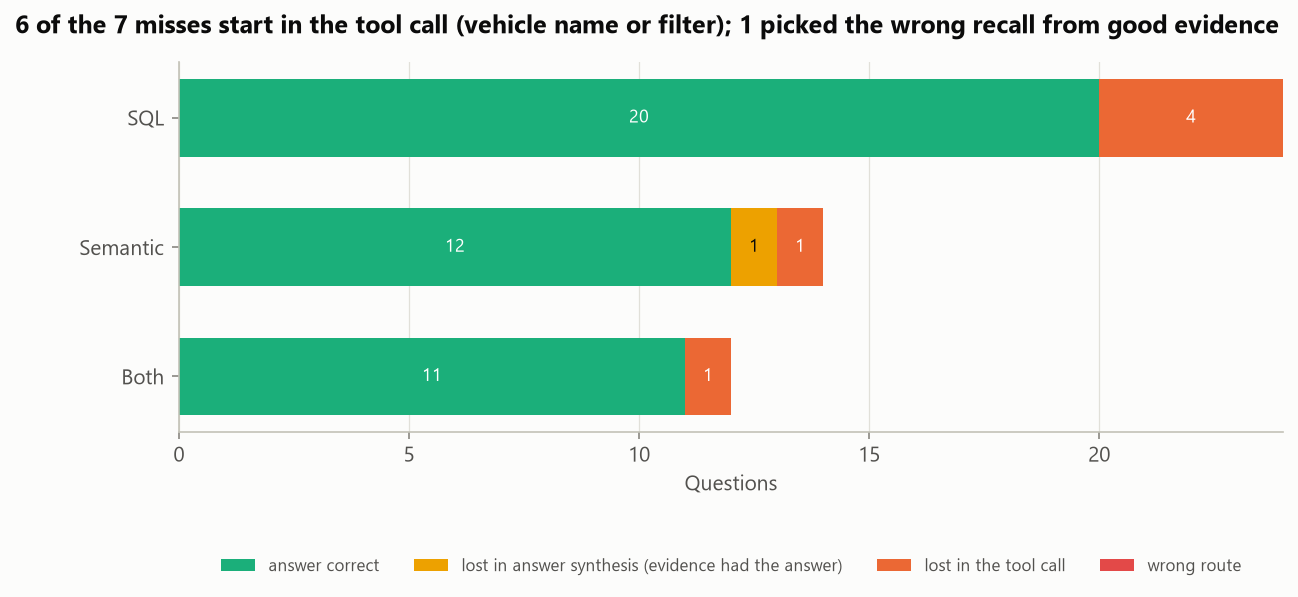

In [9]:
display(Image(FIG / '02_failure_stages.png'))

## Validation and retries

The validator rejected the first plan of 11 questions. Retries fixed 8: four rankings that also filtered on a component,
three `potential_units` measures for "how many recall campaigns" questions, and one invented model name. The three
dropped model suffixes were never fixed. Overall, tool calls valid on the first plan rose from 39 of 50 (0.78) to 47
of 50 (0.94) after retries.

The grounding check flagged 2 of 47 first drafts. Both contained a garbled vehicle name (`F-15:0` for `F-150`), and
the rewrite fixed the text. One of the two had wrong evidence (the F-150 Hybrid case), so the rewrite stayed wrong.
The three other wrong drafts passed. They are faithful to evidence that answers a slightly different question. The
check compares the answer with the evidence; it cannot tell whether the evidence matches the question.

In [10]:
errs = pd.read_csv(RES / 'plan_validation_errors.csv')
first = errs[errs.attempt == 1].drop_duplicates(['qid', 'category'])
first.groupby('category').agg(questions=('qid', 'nunique'), resolved_by_retry=('resolved_by_retry', 'sum')).sort_values('questions', ascending=False)

,questions,resolved_by_retry
category,,
component filter while ranking components,4,4
measure not asked for,3,3
model name does not exist for that model year,3,0
unknown make or model,1,1


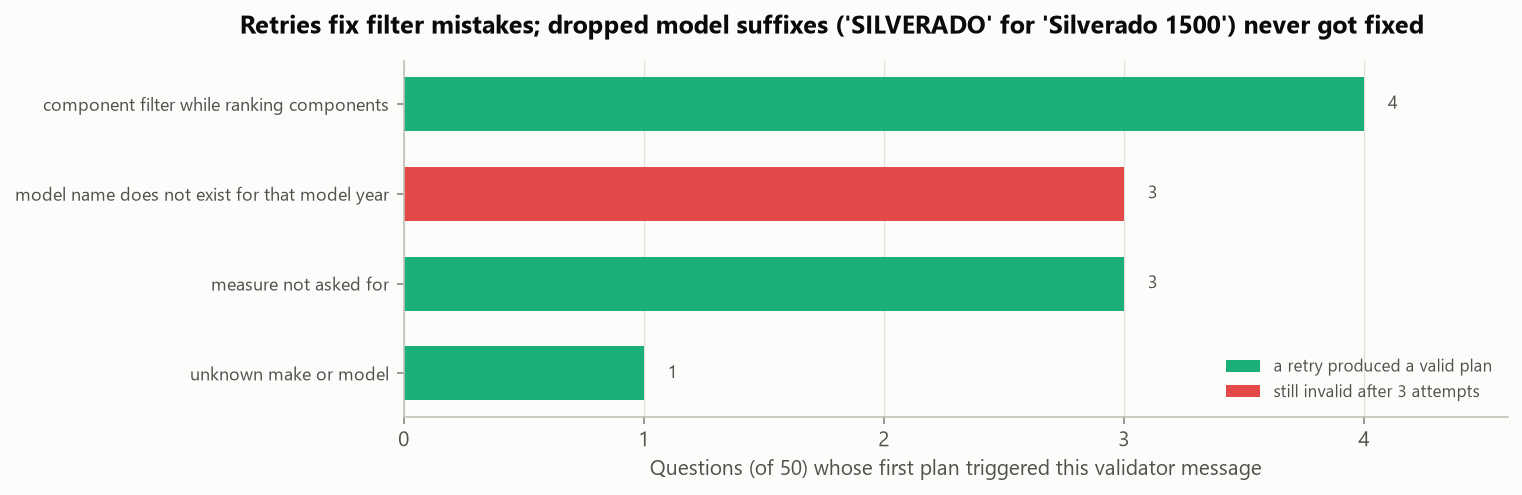

In [11]:
display(Image(FIG / '07_validation_errors.png'))

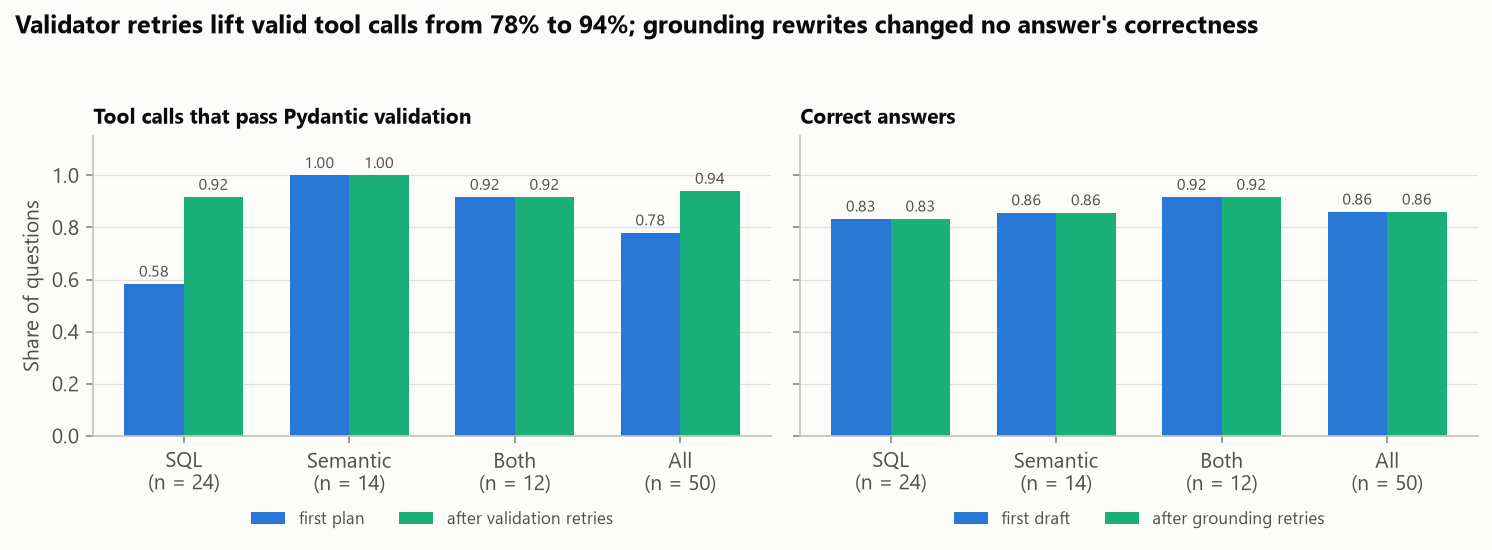

In [12]:
display(Image(FIG / '03_validation_retries.png'))

In [13]:
pd.read_csv(RES / 'grounding_check.csv')

,first,check,n,correct_after_retries
0,declined (no draft),not checked,3,0
1,first draft correct,flagged by grounding check,1,1
2,first draft correct,passed grounding check,42,42
3,first draft wrong,flagged by grounding check,1,0
4,first draft wrong,passed grounding check,3,0


## Recall search: the vehicle filter matters most

For the 26 questions whose answer is a recall campaign, five ranking strategies were compared without any LLM. With
the vehicle filter, semantic search puts the gold campaign first for 0.77 (whole question as the query) to 0.81
(component words only) of the questions, and in the top 5 for 0.96-1.00. Without the filter, the whole recall corpus
competes and hit@1 drops to 0.46. Ordering a vehicle's campaigns by date is no better than random order (hit@1 0.15
vs 0.20 expected).

In [14]:
pd.read_csv(RES / 'retrieval_summary.csv').sort_values('hit@1', ascending=False)

,strategy,hit@1,hit@3,hit@5,n
3,vehicle filter + semantic (component words),0.808,0.962,1.000,26
4,vehicle filter + semantic (question),0.769,0.846,0.962,26
0,no filter + semantic (question),0.462,0.731,0.731,26
2,vehicle filter + random order (expected),0.204,0.513,0.719,26
1,vehicle filter + newest first,0.154,0.462,0.654,26


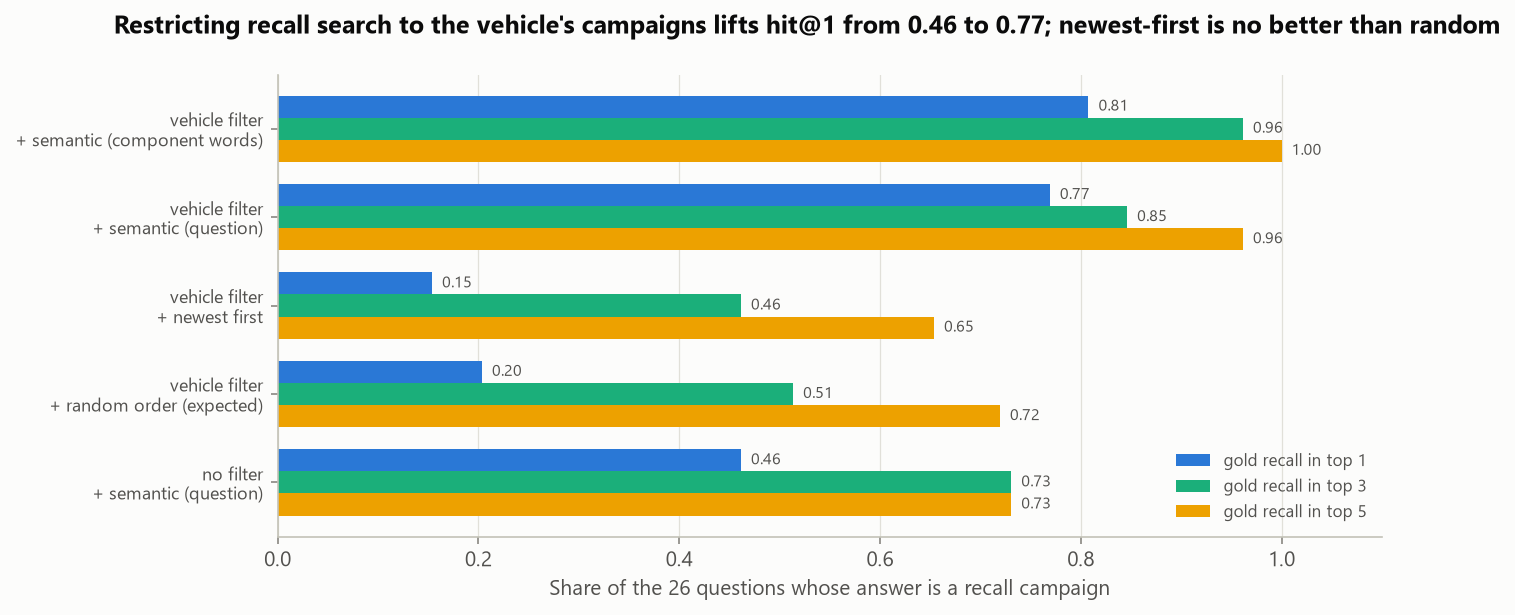

In [15]:
display(Image(FIG / '05_recall_search.png'))

## Routing

On the 50 templated questions both the LLM classify node and a keyword router are perfect, so the templates do not
test routing. On 18 separately written paraphrases the LLM routes 17 correctly; the keyword router, written for the
templates, gets 11.

In [16]:
display(pd.read_csv(RES / 'routing_accuracy.csv'))
r = pd.read_csv(RES / 'routing.csv')
r[r.set == 'separately written paraphrases'][['question', 'route_gold', 'route_llm', 'route_keyword']]

,set,router,n,accuracy
0,evaluation questions (templated),llm,50,1.000
1,evaluation questions (templated),keyword,50,1.000
2,separately written paraphrases,llm,18,0.944
3,separately written paraphrases,keyword,18,0.611


,question,route_gold,route_llm,route_keyword
50,Give me the total number of complaints filed about Subaru Outbacks from model year 2019.,sql,sql,sql
51,Rank the components that 2022 Kia Sportage owners report problems with.,sql,sql,sql
52,What's the complaint volume for the 2018 Toyota Camry so far?,sql,sql,semantic
53,Did complaints about Hyundai vehicles mention fires often in 2026? Give me the figure.,sql,sql,semantic
54,"In 2024, how many Volkswagen recalls told owners not to drive their cars?",sql,sql,sql
55,Tally the recall campaigns for the 2017 Nissan Rogue.,sql,sql,semantic
56,My 2021 Ford Bronco's airbag light is on. What did Ford recall the airbags for?,semantic,semantic,semantic
57,Tell me about the fuel pump recall on the 2019 Toyota 4Runner.,semantic,semantic,semantic
58,What can go wrong with the rearview camera on a 2020 Jeep Gladiator according to the recalls?,semantic,semantic,semantic
59,What fix is Honda offering for the 2023 Pilot's seat issue?,semantic,semantic,semantic


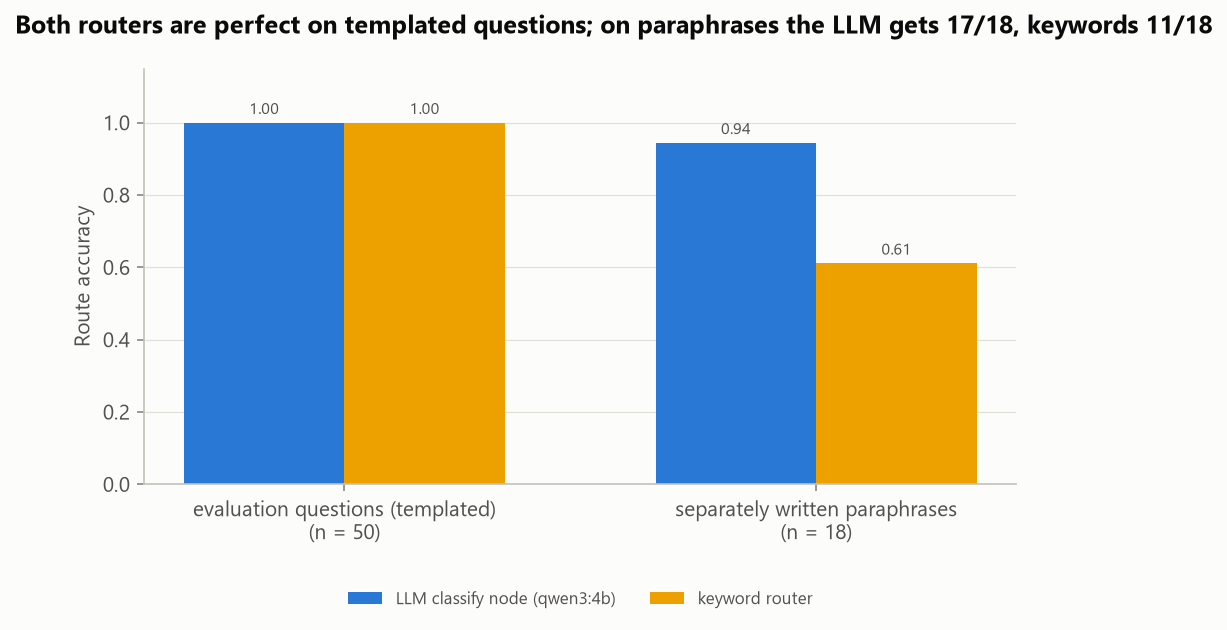

In [17]:
display(Image(FIG / '06_routing.png'))

## Latency

Latency is the model time of each LLM call (measured when the call was made and stored with the cached reply) plus
tool time. The median question takes 4.9 s (p95 7.4 s) with 3.3 LLM calls on average; `both` questions take 7.0 s
at the median. Planning is the largest share, partly because every field of the tool-call schema is required. SQL
and FAISS calls take milliseconds.

In [18]:
pd.read_csv(RES / 'latency_by_route.csv')

,route_gold,classify_s,plan_s,execute_s,answer_s,latency_s,llm_calls,latency_p50_s,latency_p95_s
0,both,0.492,4.037,0.047,2.981,7.306,3.083,7.029,9.028
1,semantic,0.441,1.482,0.043,2.734,4.700,3.000,4.812,5.167
2,sql,0.325,3.248,0.004,0.770,4.282,3.500,3.950,6.535


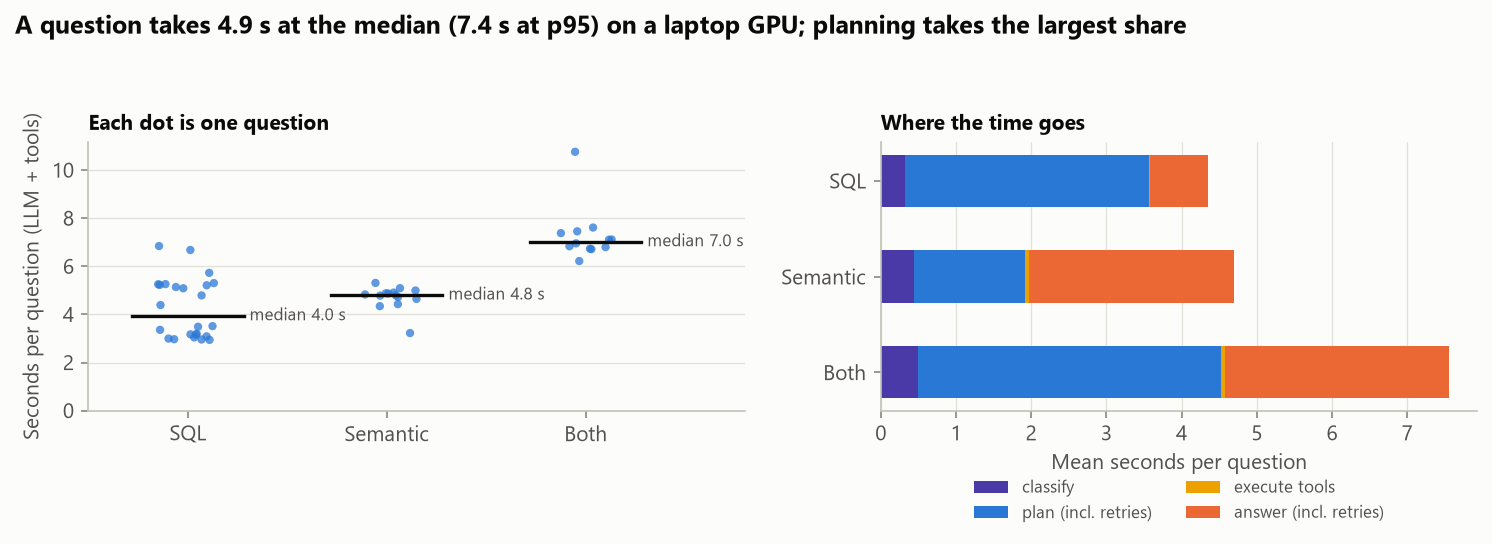

In [19]:
display(Image(FIG / '04_latency.png'))

## One trace

A recall-count question whose first plan asked for the wrong measure and was fixed by one retry:

In [20]:
traces = {json.loads(l)['qid']: json.loads(l) for l in open(RES / 'agent_traces.jsonl', encoding='utf-8')}
t = traces['recall_count_02']
print('QUESTION:', t['question'])
print('ROUTE:', t['route'], '| plan attempts:', t['plan_attempts'], '| answer attempts:', t['answer_attempts'])
for c in t['call_log']:
    print(f"plan attempt {c['attempt']} errors:", c['errors'])
print('STATS CALLS:', [{k: v for k, v in c.items() if v is not None} for c in t['stats_calls']])
print('SEARCH CALLS:', t['search_calls'])
print('SQL:', t['sql'])
print('EVIDENCE:')
for e in t['evidence'][:3]:
    print('  ', e['text'][:400])
print('ANSWER:', t['answer'])
print('CITATIONS:', t['citations'], '| grounded:', t['grounded'])

QUESTION: How many recall campaigns cover the 2022 Honda CR-V?
ROUTE: sql | plan attempts: 2 | answer attempts: 1
plan attempt 1 errors: ["stats_queries[0].measure: the question does not ask for potential_units; use 'count' to count complaints or recall campaigns"]
plan attempt 2 errors: []
STATS CALLS: [{'make': 'HONDA', 'model': 'CR-V', 'model_year': 2022, 'dataset': 'recalls', 'measure': 'count', 'limit': 5}]
SEARCH CALLS: []
SQL: ['SELECT count(*) AS value FROM (SELECT DISTINCT r.campaign AS uid, 1 AS val FROM recalls r WHERE r.campaign IN (SELECT campaign FROM recall_vehicles WHERE make = ? AND model = ? AND model_year = ?))']
EVIDENCE:
   [S1] recalls, count | filters: make=HONDA, model=CR-V, model_year=2022 | result: 3 recall campaigns
ANSWER: 3 recall campaigns
CITATIONS: ['S1'] | grounded: True


## Takeaways

1. A 4-billion-parameter local model is a usable planner and writer when SQL and search do the facts: 43 of 50
   correct, against 0 of 50 without tools.
2. Most of the remaining errors are in entity resolution, not in reasoning or arithmetic: model names with suffixes
   (Silverado 1500, F-150 Hybrid), a brand that is also a model (Genesis), an unrequested model filter.
3. Validators that explain what is wrong recover most bad tool calls; they fail when the fix requires copying a value
   the model keeps dropping. A next step is to resolve the vehicle from the question text before planning.
4. The grounding check is cheap insurance against garbled output, but it cannot detect evidence that answers the wrong
   question.
5. For recall search, filtering by vehicle matters more than the choice of query text.